In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_excel('/kaggle/input/datasets/abdallahwagih/telco-customer-churn/Telco_customer_churn.xlsx')
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_excel('/kaggle/input/datasets/abdallahwagih/telco-customer-churn/Telco_customer_churn.xlsx')
print('Data Shape (Rows, Columns):', df.shape)
display(df.head())
df.info()

Data Shape (Rows, Columns): (7043, 33)


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

In [3]:
print('Missing Values Per Column:\n', df.isnull().sum())
print('\nDuplicate Rows Count', df.duplicated().sum())
if 'TotalCharges' in df.columns:
    df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='ceorce')
    df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)
    print("\nTotalCharges column successfully cleaned and converted to numeric!")

Missing Values Per Column:
 CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges           0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64

Duplicate Rows Count 0


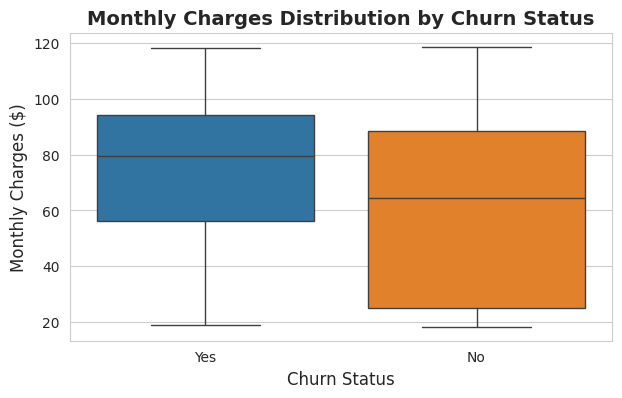

In [4]:
plt.figure(figsize=(7, 4))
sns.set_style("whitegrid")
sns.boxplot(x='Churn Label', y='Monthly Charges', data=df, hue='Churn Label', legend=False)

plt.title('Monthly Charges Distribution by Churn Status', fontsize=14, fontweight='bold')
plt.xlabel('Churn Status', fontsize=12)
plt.ylabel('Monthly Charges ($)', fontsize=12)

plt.show()

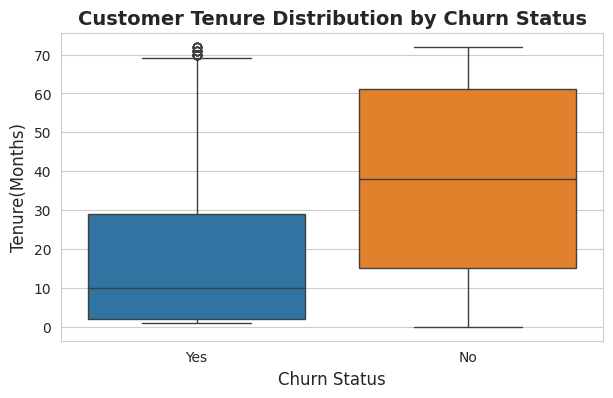

In [5]:
plt.figure(figsize=(7, 4))
sns.set_style('whitegrid')
sns.boxplot(x='Churn Label', y='Tenure Months', data=df, hue='Churn Label', legend=False)
plt.title('Customer Tenure Distribution by Churn Status', fontsize=14, fontweight='bold')
plt.xlabel('Churn Status', fontsize=12)
plt.ylabel('Tenure(Months)', fontsize=12)
plt.show()

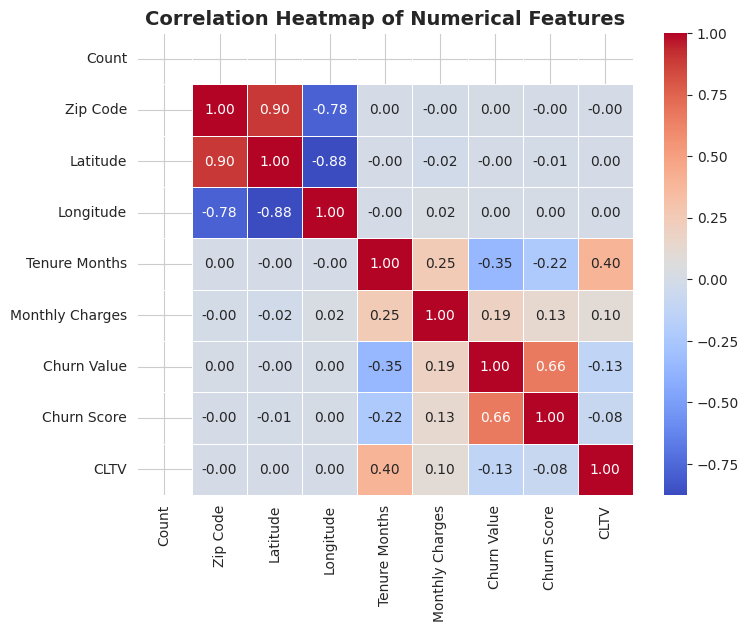

In [6]:
numeric_df = df.select_dtypes(include=['float64','int64'])
corr_matrix = numeric_df.corr()
plt.figure(figsize=(8, 6))
sns.set_style('whitegrid')
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features', fontsize=14, fontweight='bold')
plt.show()

📊 Telco Customer Churn Analysis & Business Insights
Project Overview
An end-to-end exploratory data analysis (EDA) and data cleaning project built to identify key drivers of customer churn in a telecommunications company. The objective is to uncover behavioral patterns and pricing factors contributing to customer attrition, providing actionable insights for business retention strategies.

🛠️ Tech Stack & Libraries
Language: Python

Data Manipulation: Pandas, NumPy

Data Visualization: Seaborn, Matplotlib

Environment: Kaggle Notebooks / Jupyter

🧹 Data Preparation & Cleaning
Handled data type conversions (converting string/object columns into appropriate numeric formats like Total Charges).

Resolved column naming inconsistencies, missing values, and data formatting bugs to ensure a robust dataset for analysis.

Filtered and structured numeric subsets for statistical correlation checks.

📈 Key Analytical Findings (Visualizations)
Customer Churn Distribution (Count Plot): Visualized the baseline proportion of retained vs. churned customers to understand overall attrition scale.

Monthly Charges vs. Churn (Box Plot): Discovered that customers who churned tended to have significantly higher monthly bills, pointing towards pricing sensitivity or dissatisfaction with higher-tier plans.

Customer Tenure vs. Churn (Box Plot): Revealed that customers with shorter tenure (newer subscribers) have a much higher dropout rate, highlighting a critical window for onboarding and customer engagement.

Correlation Heatmap: Analyzed numeric interactions to identify relationships between account tenure, monthly expenditure, and total lifetime value.
Business Impact / Recommendations
Targeted Onboarding: Since newer customers exhibit higher churn rates, introducing special onboarding discounts or support within the first few months can drastically improve retention.

Pricing Strategy Review: High monthly charges drive customers away; offering flexible billing tiers or customized loyalty packages for high-paying customers can mitigate churn.